# Interpolation et recalage

In [1]:
import numpy as np
import skimage.io as io
from numpy.linalg import norm
import matplotlib.pyplot as plt
from skimage.transform import rotate
from skimage.util import img_as_ubyte, img_as_float
from skimage import transform
from skimage.util import random_noise
from scipy.ndimage import convolve
from skimage.morphology import disk

## Comparaison de plusieurs types d'interpolation

In [2]:
# Image d'échiquier
if False:

    # Taille de l'image et d'un carré
    N, S = 20, 5

    nx, ny = np.meshgrid(range(N), range(N))
    x = ((nx/S) % 2 >= 1)
    y = ((ny/S) % 2 <  1)
    img = 255 * (x != y)
    
    plt.figure()
    plt.imshow(img, "gray")
    plt.colorbar()
    plt.show()

    io.imsave("echiquier.png", img_as_ubyte(img))

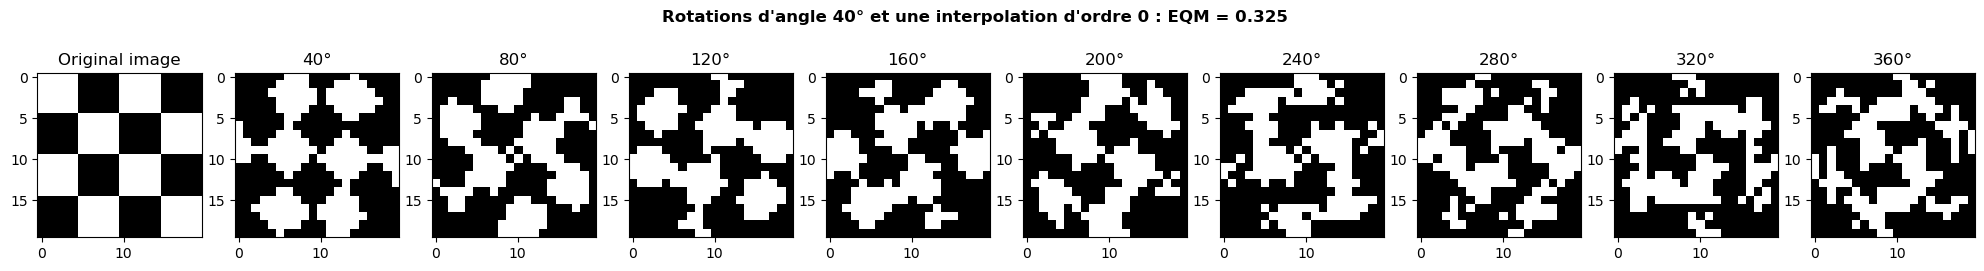

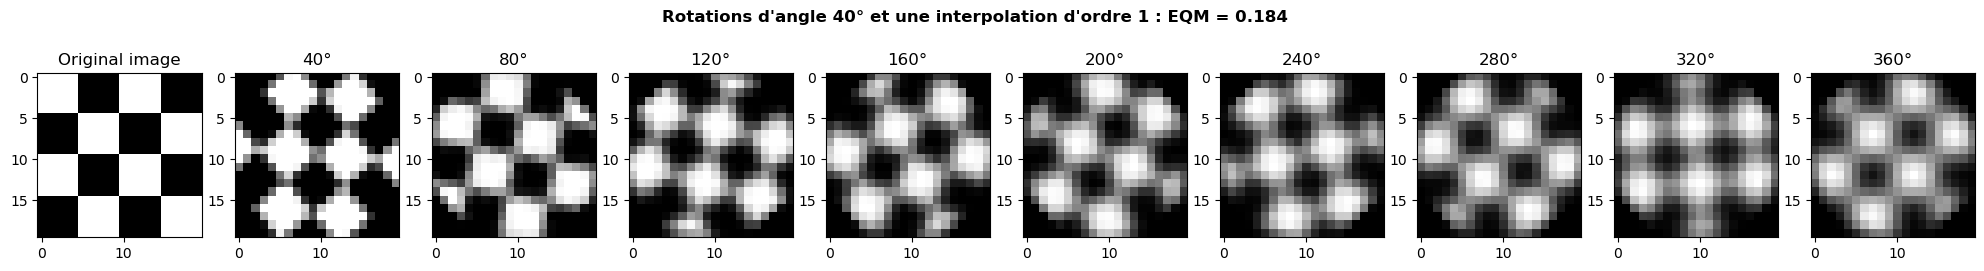

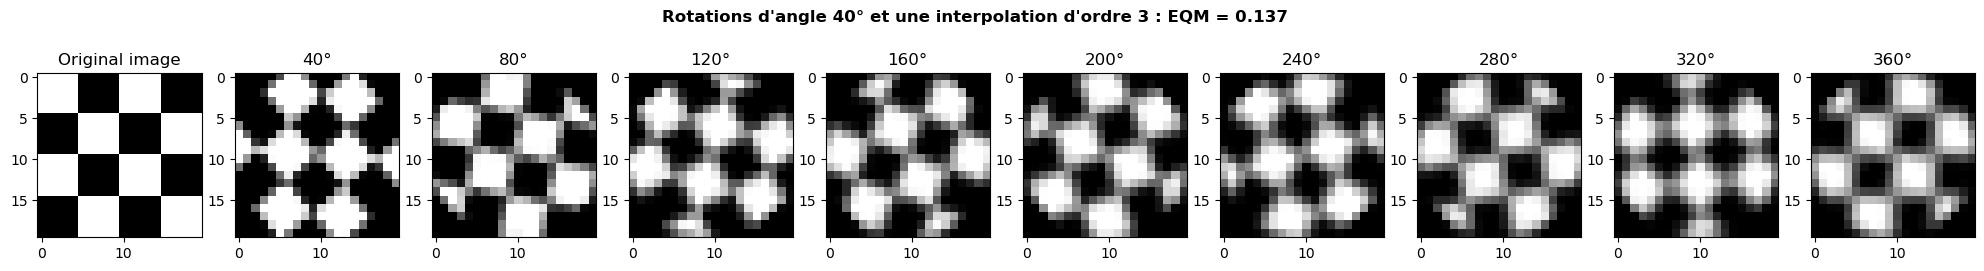

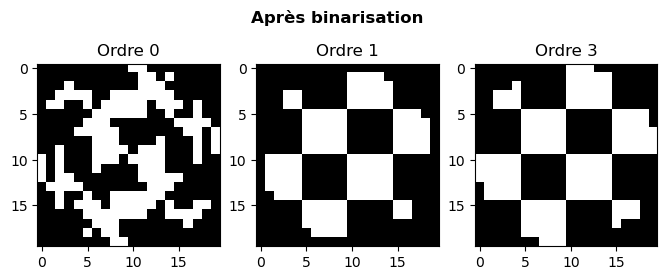

In [3]:
# Rotation
def rot(img, step, order):
    # img   : image to rotate
    # step  : angle step
    # order : interpolation order
    
    # Number of rotation to perform
    I = 360//step
    
    # Subplots
    fig, axs = plt.subplots(1,I+1,figsize=(25,3))
        
    # Initial image (in float)
    x = img_as_float(img)
    y = x.copy()
    axs[0].imshow(x, "gray")
    axs[0].set_title("Original image")

    # Rotations
    for i in range(I):
        y = rotate(y, angle=step, order=order)
        axs[i+1].imshow(y, "gray")
        axs[i+1].set_title(f"{step*(i+1)}°")
    
    # Mean square error
    M, N = x.shape
    mse = norm(x-y)**2 / (M*N)
    fig.suptitle(f"Rotations d'angle {step}° et une interpolation d'ordre {order} : EQM = {mse:.3f}", weight="bold")
    
    # Affichage final
    plt.show()

    # Retourne la dernière transformation
    return y

# Test de différentes interpolations
step = 40
img = io.imread("../_static/echiquier.png")
y0 = rot(img, step, 0)
y1 = rot(img, step, 1)
y3 = rot(img, step, 3)

# Si on considère que l'image est un masque, affiche une binarisation des interpolations (sauf celle au plus proche voisin)
fig, axs = plt.subplots(1,3,figsize=(8,3))
axs[0].imshow(y0, "gray")
axs[0].set_title("Ordre 0")
axs[1].imshow(y1>.5, "gray")
axs[1].set_title("Ordre 1")
axs[2].imshow(y3>.5, "gray")
axs[2].set_title("Ordre 3")
fig.suptitle("Après binarisation", weight="bold")
plt.show()

## Comparaison de plusieurs transformations géométriques

In [4]:
def myimshow(img, params, title):
    """Affichage perso"""

    # Figure
    fig, axs = plt.subplots(1, 2, figsize=(7,3))

    # Matrice de déformation
    M, N = params.shape
    for m in range(M):
        for n in range(N):
            
            txt = f"{params[m,n]:.3f}"

            # Supprimer les 0 décimaux non nécessaires
            while txt[-1] == "0":
                txt = txt[:-1]

            # Texte
            axs[0].text(n, m, txt, va="center", ha="center", color="k", size=12)
            
    axs[0].set_xlim(-.5, N-.5)
    axs[0].set_ylim(-.5, M-.5)
    axs[0].set_xticks([])
    axs[0].set_yticks([])
    axs[0].invert_yaxis()

    # Image
    axs[1].imshow(img)
    
    # Titre
    fig.suptitle(title)

    plt.show()

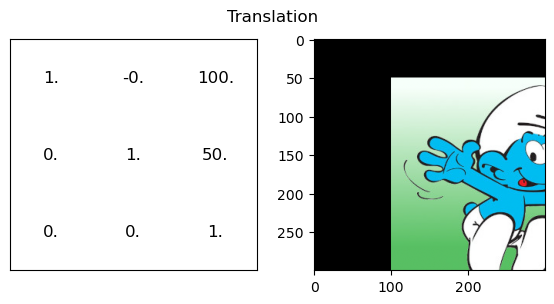

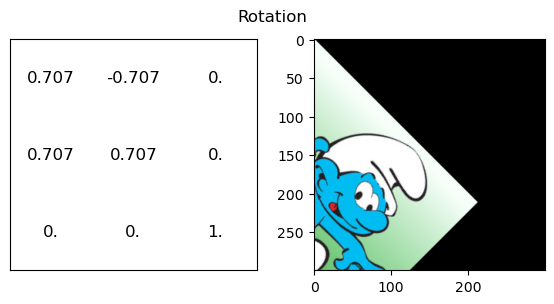

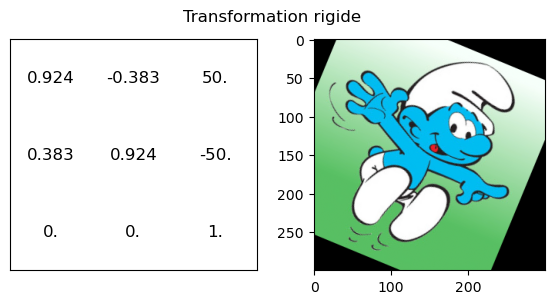

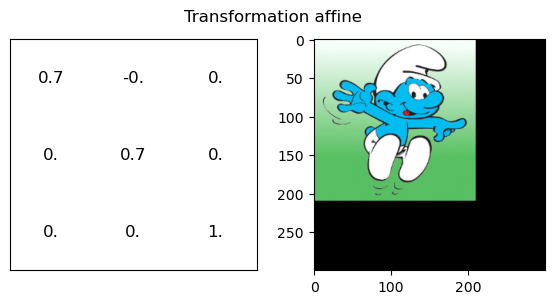

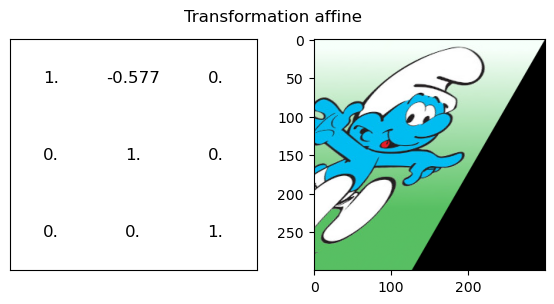

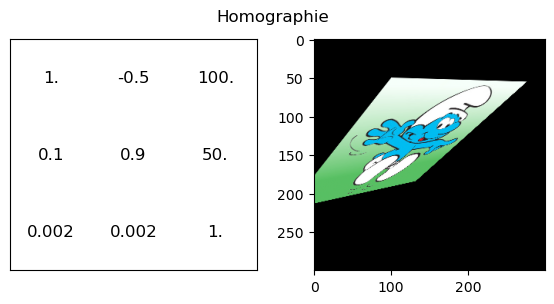

In [5]:
# Image
img = io.imread("../_static/schtroumpf.jpg")

# Translation
tform = transform.EuclideanTransform(translation=(100, 50))
interpolated = transform.warp(img, tform.inverse)
myimshow(interpolated, tform.params, "Translation")

# Rotation
tform = transform.EuclideanTransform(rotation=np.pi/4)
interpolated = transform.warp(img, tform.inverse)
myimshow(interpolated, tform.params, "Rotation")

# Transformation rigide
tform = transform.EuclideanTransform(rotation=np.pi/8, translation=(50, -50))
interpolated = transform.warp(img, tform.inverse)
myimshow(interpolated, tform.params, "Transformation rigide")

# Transformation affine
tform = transform.AffineTransform(scale=.7)
interpolated = transform.warp(img, tform.inverse)
myimshow(interpolated, tform.params, "Transformation affine")

# Transformation affine
tform = transform.AffineTransform(shear=np.pi/6)
interpolated = transform.warp(img, tform.inverse)
myimshow(interpolated, tform.params, "Transformation affine")

# Homographie
matrix = np.array([[1, -0.5, 100], [0.1, 0.9, 50], [0.0015, 0.0015, 1]])
tform = transform.ProjectiveTransform(matrix=matrix)
interpolated = transform.warp(img, tform.inverse)
myimshow(interpolated, tform.params, "Homographie")

## Recalage

In [6]:
# Image dégradée
if False:

    # Image originale
    img = io.imread("../_static/irm1.png")

    # Enlève la patate blanche (ça me permet de distinguer les deux images)
    rot = img.copy()
    M, N = rot.shape
    m, n = np.meshgrid(range(M), range(N))
    mask = (m-70)**2 + (n-75)**2 > 10**2
    rot = rot * mask

    # Rotation
    rot = rotate(rot, angle=41.5, order=3)

    # Flou
    h = disk(5)
    rot = convolve(rot, h, mode="wrap")

    # Bruit
    rot = random_noise(rot, mode='gaussian', clip=False, var=10)

    # Affichage
    plt.imshow(rot, "gray")
    plt.show()

    # Enregistrement
    rot = (rot - rot.min()) / (rot.max() - rot.min())    
    rot = img_as_ubyte(rot)
    io.imsave("../_static/irm2.png", rot)

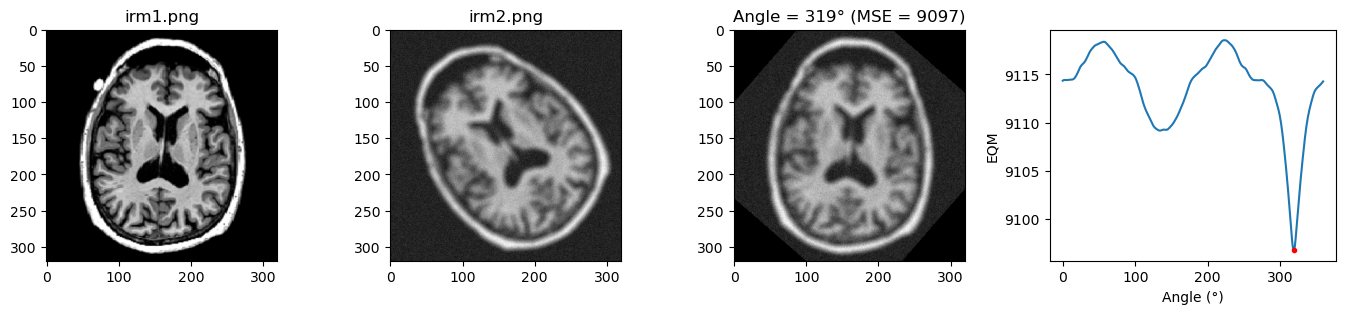

In [7]:
# Chargement des images
img1 = io.imread("../_static/irm1.png")
img2 = io.imread("../_static/irm2.png")
M, N = img1.shape

# Test des différents angles
angles = range(0, 360, 1)
N = len(angles)
mses = np.zeros(N)
for n in range(N):
    test = rotate(img2, angle=angles[n], order=3)
    mses[n] = norm(test-img1)**2 / (M*N)

# Meilleure transformation
best = np.argmin(mses)
img2_reg = rotate(img2, angle=angles[best], order=0)

# Affichage
fig, axs = plt.subplots(1,4,figsize=(17,3))
axs[0].imshow(img1, "gray")
axs[0].set_title("irm1.png")
axs[1].imshow(img2, "gray")
axs[1].set_title("irm2.png")
axs[2].imshow(img2_reg, "gray")
axs[2].set_title(f"Angle = {angles[best]}° (MSE = {mses[best]:.0f})")
axs[3].plot(angles, mses)
axs[3].plot(angles[best], mses[best], 'r.')
axs[3].set_xlabel("Angle (°)")
axs[3].set_ylabel("EQM")
plt.show()